# Diagnóstico de Marca Empleadora — Deutsche Bank vs. peers
## Sentiment analysis (transformers) + Topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de Deutsche Bank como empleador a partir de lo que dicen sus empleados en Glassdoor, y compararlos con sus competidores directos.

**Peers elegidos:** J-P-Morgan, Barclays, Citi y HSBC-Holdings. Bancos globales con banca de inversión y corporativa, presencia fuerte en UK y perfil de empleado parecido a Deutsche Bank.

| Sección | Contenido |
|---|---|
| 0 | Configuración y carga de datos |
| 1 | Preparación de variables |
| 2 | EDA |
| 3 | Sentimiento en pros y cons |
| 4 | Topic modeling con BERTopic |
| 5 | Comparación con peers |
| 6 | Empleados actuales vs. antiguos |
| 7 | Conclusiones y recomendaciones |

In [1]:
# Celda de inicialización: Instalación de dependencias si es necesario
import sys

# El flag -q lo hace silencioso, --upgrade asegura que busque las versiones correctas
# y -r apunta a tu archivo de requerimientos
%pip install -q --upgrade -r requirements.txt
%pip install pyarrow fastparquet pandas

print("¡Dependencias instaladas y actualizadas correctamente!")


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


Note: you may need to restart the kernel to use updated packages.
¡Dependencias instaladas y actualizadas correctamente!


In [2]:
# explicación: importamos todo lo necesario y fijamos la semilla para reproducibilidad.
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Configuración de alertas y estilos visuales
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)


In [3]:
# explicación: empresas objetivo y peers. Se eligen por perfil comparable a Deutsche Bank.
TARGET = "Deutsche-Bank"
PEERS = ["J-P-Morgan", "Barclays", "Citi", "HSBC-Holdings"]
FIRMS = [TARGET] + PEERS

# explicación: bajamos a 100 reseñas por empresa. Ajustable cuando queramos ampliar.
MAX_POR_EMPRESA = 500


In [4]:
# Rutas relativas al notebook (funciona igual en local y en GitHub)
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW   = BASE_DIR / "data" / "raw" / "glassdoor_reviews_hr.parquet"
DATA_PROC  = BASE_DIR / "data" / "processed"
OUT_FIG    = BASE_DIR / "outputs" / "figures"
OUT_TAB    = BASE_DIR / "outputs" / "tables"

# Ubicación del dataset original
DATA_RAW_FILE = BASE_DIR / "data" / "raw" / "glassdoor_reviews_hr.parquet"

# Lista completa de directorios del portafolio
folders = [
    "data/raw",
    "data/interim",
    "data/processed",
    "data/samples",
    "notebooks",
    "src",
    "outputs/figures",
    "outputs/tables",
    "outputs/models",
    "outputs/reports",
    "presentation/imagenes",
    "docs",
]

# Creación automática de la estructura de carpetas
for folder in folders:
    (BASE_DIR / folder).mkdir(parents=True, exist_ok=True)

# Verificaciones de control
print("Ruta raíz del proyecto (BASE_DIR):", BASE_DIR)
print("¿El archivo Parquet base existe?:", DATA_RAW_FILE.exists())
print("¡Estructura de carpetas verificada y creada exitosamente!")



Ruta raíz del proyecto (BASE_DIR): c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora
¿El archivo Parquet base existe?: True
¡Estructura de carpetas verificada y creada exitosamente!


In [5]:
# 1. Definir la ruta completa del archivo Parquet
ruta_parquet = r"C:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\data\raw\glassdoor_reviews_hr.parquet"

# 2. Definir la ruta completa donde quieres guardar el CSV (en la misma carpeta)
ruta_csv = r"C:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\data\raw\glassdoor_reviews_hr.csv"

# 3. Leer el archivo parquet
df = pd.read_parquet(ruta_parquet)

print("¡Ruta definida con éxito!")

¡Ruta definida con éxito!


In [6]:
# explicación: leemos solo las empresas que nos interesan usando el filtro del parquet.
# Si el parquet no está disponible, se puede cargar un CSV como fallback.
if DATA_RAW_FILE.exists():
    raw = pd.read_parquet(DATA_RAW_FILE, filters=[("firm", "in", FIRMS)])
else:
    # fallback por si algún día se usa un CSV muestreado
    csv_path = BASE_DIR / "data" / "raw" / "glassdoor_reviews_hr.csv"
    raw = pd.read_csv(csv_path)
    raw = raw[raw["firm"].isin(FIRMS)]

print("Reseñas disponibles por empresa:")
print(raw["firm"].value_counts())


Reseñas disponibles por empresa:
firm
Citi             14609
J-P-Morgan       11100
Barclays          9863
HSBC-Holdings     6404
Deutsche-Bank     5474
Name: count, dtype: int64


In [7]:
# explicación: muestreamos un número fijo por empresa para evitar que la empresa
# con más reseñas domine el modelo de topics conjunto.
df = (
    pd.concat(
        [g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
         for _, g in raw.groupby("firm")],
        ignore_index=True,
    )
    .sample(frac=1, random_state=SEED)   # barajamos para evitar orden por empresa
    .reset_index(drop=True)
)

print(f"Muestra de trabajo: {len(df):,} reseñas")
print(df["firm"].value_counts())
df.head(3)

Muestra de trabajo: 2,500 reseñas
firm
Deutsche-Bank    500
J-P-Morgan       500
HSBC-Holdings    500
Citi             500
Barclays         500
Name: count, dtype: int64


,firm,date_review,current,overall_rating,recommend,pros,cons
0,Deutsche-Bank,2020-08-19,"Current Employee, less than 1 year",5.0,v,work life balance even in sales,"No cons as such, best place and best manager t..."
1,Deutsche-Bank,2022-09-16,Current Employee,3.0,x,Good compensation & friendly team,Promotion opportunities are minimal. Very few ...
2,Deutsche-Bank,2021-01-10,Former Employee,4.0,o,"Flexible timings, good work life balance","No growth after a point, and not much to learn"


In [8]:
# explicación: la columna 'current' mezcla situación y antigüedad. La separamos.
def parse_situacion(s: str) -> str:
    s = str(s).lower()
    if s.startswith("current"):
        return "Actual"
    if s.startswith("former"):
        return "Antiguo"
    return "Desconocido"

def parse_antiguedad(s: str) -> str:
    m = re.search(r"(less|more) than (\d+) year", str(s))
    return f"{m.group(1)} than {m.group(2)}y" if m else "n/d"

df["situacion"]  = df["current"].map(parse_situacion)
df["antiguedad"] = df["current"].map(parse_antiguedad)

# explicación: 'recommend' viene codificado: v = sí, o = neutral, x = no.
df["recomienda"] = df["recommend"].map({"v": "Sí", "o": "Neutral", "x": "No"})

df["date_review"] = pd.to_datetime(df["date_review"], errors="coerce")
df["anio"] = df["date_review"].dt.year

# explicación: limpieza mínima de textos. No lematizamos porque BERTopic usa embeddings.
for col in ["pros", "cons"]:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

print(df["situacion"].value_counts())
print(df["recomienda"].value_counts(dropna=False))
df.head(3)

situacion
Actual     1586
Antiguo     914
Name: count, dtype: int64
recomienda
Sí         1165
Neutral     922
No          413
Name: count, dtype: int64


,firm,date_review,current,overall_rating,recommend,pros,cons,situacion,antiguedad,recomienda,anio
0,Deutsche-Bank,2020-08-19,"Current Employee, less than 1 year",5.0,v,work life balance even in sales,"No cons as such, best place and best manager t...",Actual,less than 1y,Sí,2020
1,Deutsche-Bank,2022-09-16,Current Employee,3.0,x,Good compensation & friendly team,Promotion opportunities are minimal. Very few ...,Actual,n/d,No,2022
2,Deutsche-Bank,2021-01-10,Former Employee,4.0,o,"Flexible timings, good work life balance","No growth after a point, and not much to learn",Antiguo,n/d,Neutral,2021


In [9]:
# explicación: guardamos el dataset preparado para no repetir la carga en cada iteración.
proc_path = DATA_PROC / "resenas_preparadas.parquet"
df.to_parquet(proc_path, index=False)
print("Guardado en:", proc_path)

Guardado en: c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\data\processed\resenas_preparadas.parquet


---
## 1. EDA — Contexto de Deutsche Bank vs. peers

Objetivo: entender el punto de partida antes de modelar.
- nº de reseñas por empresa en la muestra
- rating medio
- % de recomendación
- reparto actuales vs. antiguos
- evolución temporal del rating

In [10]:
# explicación: agregamos métricas clave por empresa.
def resumen_firm(g: pd.DataFrame) -> pd.Series:
    total = len(g)
    return pd.Series({
        "n_resenas": total,
        "rating_medio": g["overall_rating"].mean(),
        "pct_recomienda": (g["recomienda"] == "Sí").mean() * 100,
        "pct_no_recomienda": (g["recomienda"] == "No").mean() * 100,
        "pct_actuales": (g["situacion"] == "Actual").mean() * 100,
        "rating_actuales": g.loc[g["situacion"] == "Actual", "overall_rating"].mean(),
        "rating_antiguos": g.loc[g["situacion"] == "Antiguo", "overall_rating"].mean(),
    })

resumen = df.groupby("firm").apply(resumen_firm).round(2)
resumen = resumen.loc[FIRMS]  # orden controlado
resumen.to_csv(OUT_TAB / "resumen_empresas.csv")
resumen

,n_resenas,rating_medio,pct_recomienda,pct_no_recomienda,pct_actuales,rating_actuales,rating_antiguos
firm,,,,,,,
Deutsche-Bank,500.0,3.73,41.4,20.4,62.0,3.83,3.58
J-P-Morgan,500.0,3.91,52.6,14.2,63.8,4.02,3.70
Barclays,500.0,3.90,47.0,12.8,67.6,3.97,3.74
Citi,500.0,3.70,42.8,19.2,63.2,3.89,3.36
HSBC-Holdings,500.0,3.72,49.2,16.0,60.6,3.85,3.51


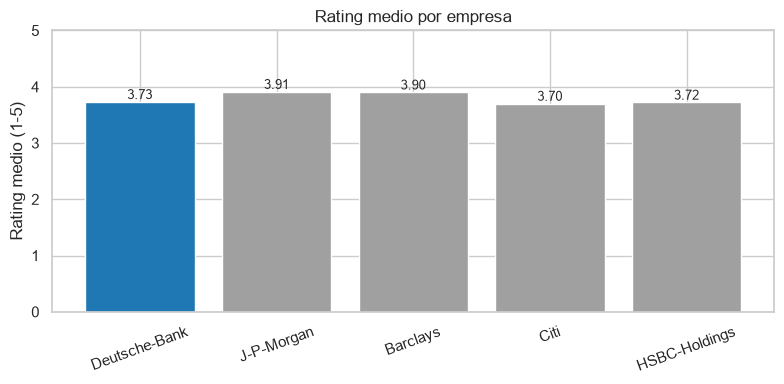

In [11]:
# explicación: gráfico de barras simple para que RRHH vea de un vistazo la posición relativa.
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#1f77b4" if f == TARGET else "#a0a0a0" for f in resumen.index]
ax.bar(resumen.index, resumen["rating_medio"], color=colors)
ax.set_title("Rating medio por empresa")
ax.set_ylabel("Rating medio (1-5)")
ax.set_ylim(0, 5)
for i, v in enumerate(resumen["rating_medio"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUT_FIG / "eda_rating_medio.png", dpi=150, bbox_inches="tight")
plt.show()

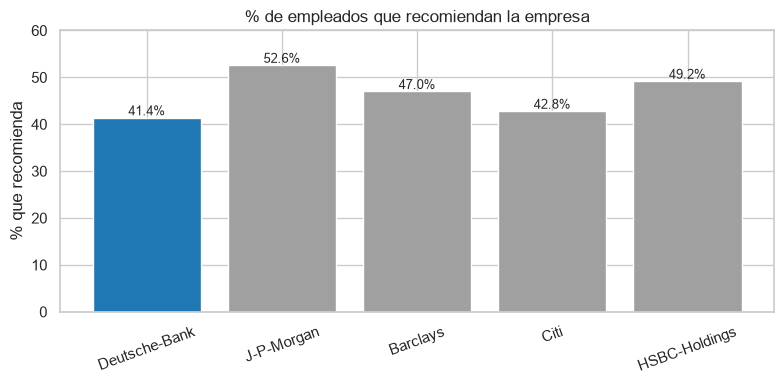

In [12]:
# explicación: gráfico de barras del % de recomendación por empresa.
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#1f77b4" if f == TARGET else "#a0a0a0" for f in resumen.index]
ax.bar(resumen.index, resumen["pct_recomienda"], color=colors)
ax.set_title("% de empleados que recomiendan la empresa")
ax.set_ylabel("% que recomienda")
ax.set_ylim(0, 60)
for i, v in enumerate(resumen["pct_recomienda"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUT_FIG / "pct_recomienda.png", dpi=150, bbox_inches="tight")
plt.show()

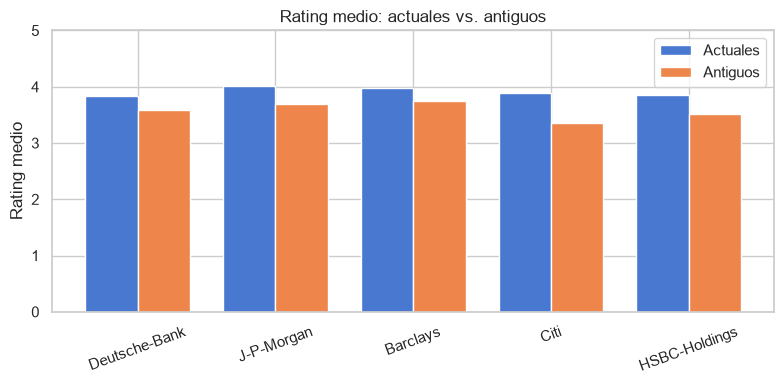

In [13]:
# explicación: comparamos cómo puntúan los actuales vs los antiguos en cada empresa.
# Nota: los antiguos suelen puntuar más bajo (sesgo de selección).
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(resumen.index))
w = 0.38
ax.bar(x - w/2, resumen["rating_actuales"], width=w, label="Actuales")
ax.bar(x + w/2, resumen["rating_antiguos"], width=w, label="Antiguos")
ax.set_xticks(x)
ax.set_xticklabels(resumen.index, rotation=20)
ax.set_ylabel("Rating medio")
ax.set_title("Rating medio: actuales vs. antiguos")
ax.set_ylim(0, 5)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "eda_actuales_vs_antiguos.png", dpi=150, bbox_inches="tight")
plt.show()

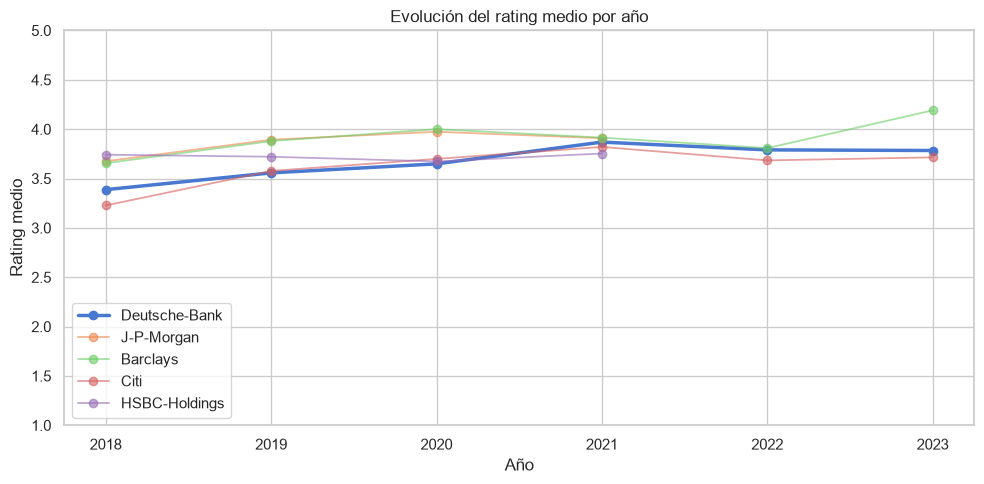

In [14]:
# explicación: vemos si hay años problemáticos. Se filtra a partir de 2018 por el alcance del dataset.
evol = (
    df[df["anio"] >= 2018]
    .groupby(["firm", "anio"])["overall_rating"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
for firm in FIRMS:
    sub = evol[evol["firm"] == firm]
    lw = 2.5 if firm == TARGET else 1.3
    alpha = 1.0 if firm == TARGET else 0.6
    ax.plot(sub["anio"], sub["overall_rating"], marker="o",
            label=firm, linewidth=lw, alpha=alpha)
ax.set_title("Evolución del rating medio por año")
ax.set_ylabel("Rating medio")
ax.set_xlabel("Año")
ax.set_ylim(1, 5)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "eda_evolucion_rating.png", dpi=150, bbox_inches="tight")
plt.show()

**Primeras conclusiones del EDA:**
**Conclusiones del EDA:**
- Deutsche Bank tiene el % de recomendación más bajo (41.4%) y el más alto de no-recomendación (20.4%) de los 5 bancos.
- En rating medio DB está en 3.73, en el grupo bajo con Citi (3.70) y HSBC (3.72), claramente por debajo de J-P-Morgan (3.91) y Barclays (3.90).
- La brecha actuales vs. antiguos es de 0.25 puntos, sobre una base baja. DB tiene un problema de recomendación, no solo de fuga.
- Con 500 reseñas por empresa (2500 total) las diferencias son sólidas.

---
## 2. Sentimiento en pros y cons (control de calidad)

Usamos `distilbert-base-uncased-finetuned-sst-2-english`, modelo binario (POSITIVE / NEGATIVE).
- `truncation=True` y `max_length=512` para evitar errores con reseñas largas.
- Esperamos: mayoría de pros → POSITIVE, mayoría de cons → NEGATIVE.
- Si no es así, revisamos casos discordantes.

In [15]:
# explicación: importamos el pipeline dentro de la celda para que el notebook no falle
# si el usuario decide no ejecutar la sección de sentimiento.
from transformers import pipeline
import torch

DEVICE = 0 if torch.cuda.is_available() else -1
print("Dispositivo:", "GPU" if DEVICE == 0 else "CPU")

sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=DEVICE,
)

def score_sentiment(texts, batch_size=32):
    """Devuelve lista de (label, score) usando truncado a 512 tokens."""
    results = sentiment_pipe(
        list(texts),
        truncation=True,
        max_length=512,
        batch_size=batch_size,
    )
    return results

Dispositivo: CPU


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 21767.93it/s]


In [16]:
# explicación: 100 x 5 empresas = 500 filas. Aplicamos a pros y cons por separado.
pros_sent = score_sentiment(df["pros"].tolist())
cons_sent = score_sentiment(df["cons"].tolist())

df["pros_sent_label"] = [r["label"] for r in pros_sent]
df["pros_sent_score"] = [r["score"] for r in pros_sent]
df["cons_sent_label"] = [r["label"] for r in cons_sent]
df["cons_sent_score"] = [r["score"] for r in cons_sent]

df[["firm", "pros_sent_label", "cons_sent_label"]].head()

,firm,pros_sent_label,cons_sent_label
0,Deutsche-Bank,POSITIVE,POSITIVE
1,Deutsche-Bank,POSITIVE,NEGATIVE
2,Deutsche-Bank,POSITIVE,NEGATIVE
3,J-P-Morgan,POSITIVE,POSITIVE
4,HSBC-Holdings,POSITIVE,NEGATIVE


In [17]:
# explicación: % de pros POSITIVOS y % de cons NEGATIVOS. Debería ser alto.
valid = (
    df.groupby("firm")
      .apply(lambda g: pd.Series({
          "pct_pros_positivos": (g["pros_sent_label"] == "POSITIVE").mean() * 100,
          "pct_cons_negativos": (g["cons_sent_label"] == "NEGATIVE").mean() * 100,
      }))
      .round(1)
      .loc[FIRMS]
)
valid.to_csv(OUT_TAB / "validacion_sentimiento.csv")
valid

,pct_pros_positivos,pct_cons_negativos
firm,,
Deutsche-Bank,91.6,83.6
J-P-Morgan,95.0,81.2
Barclays,94.2,80.8
Citi,91.6,84.8
HSBC-Holdings,92.8,81.6


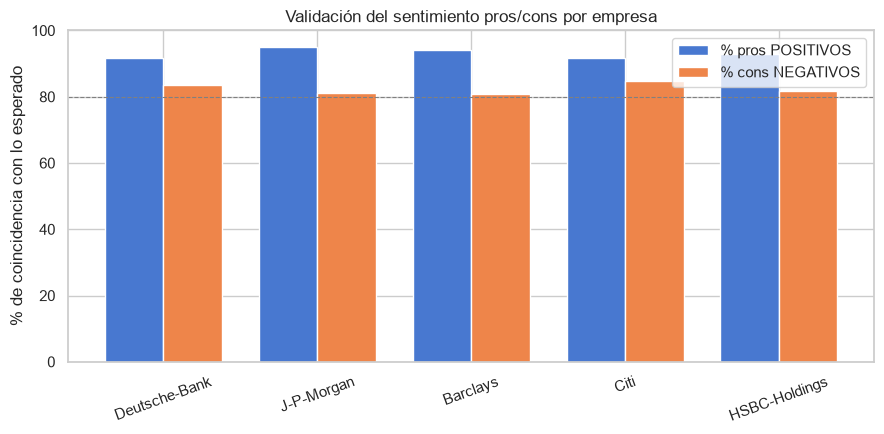

In [18]:
# explicación: validamos visualmente el sentimiento por empresa.
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(valid.index))
w = 0.38
ax.bar(x - w/2, valid["pct_pros_positivos"], width=w, label="% pros POSITIVOS")
ax.bar(x + w/2, valid["pct_cons_negativos"], width=w, label="% cons NEGATIVOS")
ax.set_xticks(x)
ax.set_xticklabels(valid.index, rotation=20)
ax.set_ylabel("% de coincidencia con lo esperado")
ax.set_title("Validación del sentimiento pros/cons por empresa")
ax.set_ylim(0, 100)
ax.axhline(80, color="grey", lw=0.8, ls="--")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "validacion_sentimiento.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# explicación: revisamos ejemplos donde el modelo no coincide con lo esperado.
# Esto es un control de calidad: si hay muchos, algo falla (texto truncado, ironía, "no cons"...).

discordantes = df[
    (df["pros_sent_label"] == "NEGATIVE") |
    (df["cons_sent_label"] == "POSITIVE")
][["firm", "pros", "pros_sent_label",
   "cons", "cons_sent_label"]]

print(f"Casos discordantes: {len(discordantes)} de {len(df)}")
discordantes.head(8)

Casos discordantes: 589 de 2500


,firm,pros,pros_sent_label,cons,cons_sent_label
0,Deutsche-Bank,work life balance even in sales,POSITIVE,"No cons as such, best place and best manager t...",POSITIVE
3,J-P-Morgan,Compensation and benefits are good,POSITIVE,"work life balance, work timings",POSITIVE
5,Citi,* culture * Global opportunity * Work life bal...,POSITIVE,There is always scope for improvement,POSITIVE
8,Barclays,Only pro isworking from home,NEGATIVE,Long shifts Holidays hard to book off No break...,NEGATIVE
12,Citi,Citi takes care of right talents. Being a larg...,POSITIVE,There are many good people manager compared to...,POSITIVE
13,Deutsche-Bank,A great place to work,POSITIVE,Some hard task masters there,POSITIVE
18,Barclays,"Good salary, benefits, not much else.",NEGATIVE,Long hours working with US based division. Tec...,NEGATIVE
22,J-P-Morgan,Free HMO two DEP good pay and holidays pay,NEGATIVE,mental stress diff to get monetary support for...,NEGATIVE


---
## 3. Topic modeling con BERTopic

- Un único modelo para **pros** con las 5 empresas juntas.
- Un único modelo para **cons** con las 5 empresas juntas.
- Así los topics son comparables entre empresas (regla de comparabilidad del enunciado).
- Tratamiento de outliers: se reducen a un topic existente usando `c-tf-idf`.

**Justificación de BERTopic:** aprovecha embeddings semánticos de frases (mejor que LDA con textos cortos e informales como los de Glassdoor) y aporta representaciones por topic directamente interpretables.

In [20]:
# explicación: entrenamos BERTopic sobre los pros. Usamos un modelo de embeddings ligero
# (all-MiniLM-L6-v2) para que corra también en CPU con 500 documentos.
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

topic_model_pros = BERTopic(
    embedding_model=embedding_model,
    language="english",
    calculate_probabilities=False,
    nr_topics=15,                    # <-- AÑADIR
    verbose=True,
)

pros_docs = df["pros"].fillna("").tolist()
topics_pros, _ = topic_model_pros.fit_transform(pros_docs)
df["topic_pros"] = topics_pros

print("Nº de topics detectados en pros:", len(topic_model_pros.get_topic_info()) - 1)
topic_model_pros.get_topic_info().head(10)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19040.65it/s]
2026-10-07 20:52:53,711 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 79/79 [00:03<00:00, 24.37it/s]
2026-10-07 20:52:56,966 - BERTopic - Embedding - Completed ✓
2026-10-07 20:52:56,966 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-07 20:53:14,322 - BERTopic - Dimensionality - Completed ✓
2026-10-07 20:53:14,323 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-07 20:53:14,390 - BERTopic - Cluster - Completed ✓
2026-10-07 20:53:14,391 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-07 20:53:14,432 - BERTopic - Representation - Completed ✓
2026-10-07 20:53:14,433 - BERTopic - Topic reduction - Reducing number of topics
2026-10-07 20:53:14,438 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-07 20:53:14,468 - BERTopic - Representation - C

Nº de topics detectados en pros: 14


,Topic,Count,Name,Representation,Representative_Docs
0,-1,690,-1_and_good_to_great,"[and, good, to, great, environment, culture, o...","[Good culture to work for, Good work culture o..."
1,0,700,0_benefits_good_and_salary,"[benefits, good, and, salary, place, pay, to, ...","[Opportunities for help and training, good ben..."
2,1,417,1_balance_life_work_culture,"[balance, life, work, culture, good, and, grea...","[Work life balance, good work culture, Good wo..."
3,2,129,2_bank_the_barclays_to,"[bank, the, barclays, to, banking, of, in, you...",[The M&S Bank head office is at a lovely locat...
4,3,126,3_company_to_with_for,"[company, to, with, for, great, work, best, go...","[Great company to work for, Great company to w..."
5,4,103,4_learning_learn_career_for,"[learning, learn, career, for, to, growth, of,...","[A lot of resources to learn and growth, Great..."
6,5,94,5_team_great_teams_good,"[team, great, teams, good, and, culture, suppo...","[Good culture, work, people, team, great team ..."
7,6,62,6_flexible_home_hours_from,"[flexible, home, hours, from, work, working, f...",[Flexible to work from home and great benefits...
8,7,51,7_mobility_internal_opportunities_global,"[mobility, internal, opportunities, global, in...",[Internal mobility encouraged with great oppor...
9,8,38,8_pros_no_none_nothing,"[pros, no, none, nothing, not, any, think, con...","[There’s no pros - terrible place to work, No ..."


In [21]:
# explicación: por defecto BERTopic asigna -1 a los outliers (reseñas que no encajan).
# Los reasignamos a un topic existente con c-tf-idf para no perder señal.
new_topics_pros = topic_model_pros.reduce_outliers(
    pros_docs, topics_pros, strategy="c-tf-idf", threshold=0.0
)
topic_model_pros.update_topics(pros_docs, topics=new_topics_pros, vectorizer_model=None)
df["topic_pros"] = new_topics_pros

outliers_pct = (df["topic_pros"] == -1).mean() * 100
print(f"% outliers pros tras reducción: {outliers_pct:.1f}%")

2026-10-07 20:53:14,549 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


% outliers pros tras reducción: 0.0%


In [22]:
# explicación: mismo procedimiento para los cons.
topic_model_cons = BERTopic(
    embedding_model=embedding_model,
    language="english",
    calculate_probabilities=False,
    nr_topics=15,
    verbose=True,
)

cons_docs = df["cons"].fillna("").tolist()
topics_cons, _ = topic_model_cons.fit_transform(cons_docs)
new_topics_cons = topic_model_cons.reduce_outliers(
    cons_docs, topics_cons, strategy="c-tf-idf", threshold=0.0
)
topic_model_cons.update_topics(cons_docs, topics=new_topics_cons, vectorizer_model=None)
df["topic_cons"] = new_topics_cons

print("Nº de topics detectados en cons:", len(topic_model_cons.get_topic_info()) - 1)
topic_model_cons.get_topic_info().head(10)

2026-10-07 20:53:14,592 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 79/79 [00:04<00:00, 19.11it/s]
2026-10-07 20:53:18,740 - BERTopic - Embedding - Completed ✓
2026-10-07 20:53:18,740 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-07 20:53:25,653 - BERTopic - Dimensionality - Completed ✓
2026-10-07 20:53:25,654 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-07 20:53:25,713 - BERTopic - Cluster - Completed ✓
2026-10-07 20:53:25,714 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-07 20:53:25,773 - BERTopic - Representation - Completed ✓
2026-10-07 20:53:25,773 - BERTopic - Topic reduction - Reducing number of topics
2026-10-07 20:53:25,779 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-07 20:53:25,818 - BERTopic - Representation - Completed ✓
2026-10-07 20:53:25,820 - BERTopic - Topic reduction - Redu

Nº de topics detectados en cons: 14


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2,-1____,"[, , , , , , , , , ]","[The Recruitment (or precisely, the recruiters..."
1,0,716,0_and_the_to_of,"[and, the, to, of, management, in, is, are, to...","[No one knows what they are doing, they do not..."
2,1,523,1_salary_pay_not_growth,"[salary, pay, not, growth, is, career, and, to...",[Hard to get promoted and salary increment is ...
3,2,361,2_hours_work_long_life,"[hours, work, long, life, balance, working, an...","[Work life balance is not good, Long working h..."
4,3,181,3_cons_no_company_any,"[cons, no, company, any, as, there, such, good...","[there is no Cons, No cons in the company, No ..."
5,4,130,4_bank_the_banks_is,"[bank, the, banks, is, to, it, hsbc, other, in...",[- Most are arrogant who still hold on their a...
6,5,89,5_nothing_such_as_now,"[nothing, such, as, now, say, mention, good, b...","[nothing as such for now, Nothing as such for ..."
7,6,90,6_none_think_can_that,"[none, think, can, that, of, any, far, so, my,...","[None that i can think of, None that I can thi..."
8,7,91,7_location_office_place_work,"[location, office, place, work, from, home, wo...",[My department was moved to a location which w...
9,8,100,8_slow_processes_decision_things,"[slow, processes, decision, things, making, pr...",[Change can be slow due to inefficient process...


In [23]:
# explicación: BERTopic devuelve topics finos. RRHH necesita categorías amplias.
# Revisamos las palabras clave y asignamos manualmente cada topic a una categoría.
print("TOPICS PROS:")
for tid, words in topic_model_pros.get_topics().items():
    if tid == -1:
        continue
    print(f"[{tid}] {[w for w, _ in words[:8]]}")

print("\nTOPICS CONS:")
for tid, words in topic_model_cons.get_topics().items():
    if tid == -1:
        continue
    print(f"[{tid}] {[w for w, _ in words[:8]]}")

TOPICS PROS:
[0] ['benefits', 'good', 'and', 'to', 'place', 'pay', 'salary', 'work']
[1] ['balance', 'life', 'work', 'culture', 'good', 'and', 'great', 'is']
[2] ['the', 'bank', 'to', 'you', 'of', 'in', 'and', 'barclays']
[3] ['company', 'to', 'with', 'for', 'great', 'work', 'the', 'good']
[4] ['learn', 'learning', 'career', 'for', 'lot', 'of', 'to', 'opportunities']
[5] ['team', 'great', 'teams', 'and', 'good', 'culture', 'supportive', 'support']
[6] ['flexible', 'home', 'hours', 'working', 'from', 'work', 'flexibility', 'timings']
[7] ['mobility', 'opportunities', 'global', 'internal', 'international', 'to', 'move', 'of']
[8] ['no', 'pros', 'none', 'not', 'nothing', 'any', 'pressure', 'think']
[9] ['brand', 'name', 'value', 'good', 'amaze', 'and', 'learning', 'big']
[10] ['citi', 'the', 'organisation', 'in', 'at', 'clients', 'of', 'offers']
[11] ['hsbc', 'it', 'is', 'very', 'as', 'an', 'at', 'first']
[12] ['leaves', '10', 'amount', 'of', 'sick', 'number', 'ample', 'cool']
[13] ['on',

In [24]:

# --- 4.3 Categorización de topics ---
# 1) Si el topic está en el mapeo manual, se usa esa categoría.
# 2) Si no, se infiere por palabras clave.
# 3) Si tampoco encaja, cae a "Otros".

def categorize_topic(topic_id, topic_model, manual_map):
    """Devuelve la categoría de negocio para un topic dado."""
    if topic_id == -1:
        return "Otros"
    if topic_id in manual_map:
        return manual_map[topic_id]

    words = [w for w, _ in topic_model.get_topics().get(topic_id, [])][:10]
    text = " ".join(words).lower()

    rules = [
        (["benefit", "salary", "pay", "compensation", "bonus", "wage", "money", "reward"],
         "Compensación y beneficios"),
        (["balance", "life", "flexible", "home", "remote", "hours", "schedule"],
         "Conciliación"),
        (["culture", "environment", "atmosphere", "colleague", "people", "diversity", "inclusion"],
         "Cultura y ambiente"),
        (["career", "growth", "learning", "training", "opportunit", "development",
          "promotion", "mentor", "skill"],
         "Carrera y desarrollo"),
        (["brand", "reputation", "company", "name", "global", "prestige"],
         "Marca y reputación"),
        (["team", "office", "manager", "management", "leader", "boss", "supervisor"],
         "Equipo y personas"),
        (["bureaucrac", "politic", "slow", "process", "hierarch", "approval", "red tape"],
         "Burocracia y política interna"),
        (["workload", "stress", "pressure", "burnout", "overwork", "long hour", "busy"],
         "Carga laboral"),
        (["communicat", "align", "meeting", "feedback", "inform", "transparen"],
         "Comunicación interna"),
    ]
    for keywords, cat in rules:
        if any(k in text for k in keywords):
            return cat
    return "Otros"


# --- 4.5 Guardar topics en CSV ---
topic_model_pros.get_topic_info().to_csv(OUT_TAB / "topics_pros.csv", index=False)
topic_model_cons.get_topic_info().to_csv(OUT_TAB / "topics_cons.csv", index=False)
print(f"\nTopics guardados en {OUT_TAB}")

# --- 4.6 Aplicar categorización ---
MAP_PRO_TID_TO_CAT = {
    0:  "Compensación y beneficios",
    1:  "Conciliación",
    2:  "Cultura y ambiente",
    3:  "Carrera y desarrollo",
    4:  "Marca y reputación",
    5:  "Cultura y ambiente",
    6:  "Cultura y ambiente",
    7:  "Equipo y personas",
    8:  "Equipo y personas",
    9:  "Cultura y ambiente",
}

MAP_CON_TID_TO_CAT = {
    0: "Burocracia y política interna",
    1: "Compensación y beneficios",
    2: "Carga laboral",
    3: "Carrera y desarrollo",
    4: "Management y dirección",
    5: "Conciliación",
    6: "Otros",
    7: "Comunicación interna",
    8: "Otros",
}

df["cat_pros"] = df["topic_pros"].apply(
    lambda t: categorize_topic(t, topic_model_pros, MAP_PRO_TID_TO_CAT)
)
df["cat_cons"] = df["topic_cons"].apply(
    lambda t: categorize_topic(t, topic_model_cons, MAP_CON_TID_TO_CAT)
)

print("\nDistribución de categorías en PROS:")
print(df["cat_pros"].value_counts())
print(f"  → % Otros: {(df['cat_pros'] == 'Otros').mean() * 100:.1f}%")

print("\nDistribución de categorías en CONS:")
print(df["cat_cons"].value_counts())
print(f"  → % Otros: {(df['cat_cons'] == 'Otros').mean() * 100:.1f}%")


Topics guardados en c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\outputs\tables

Distribución de categorías en PROS:
cat_pros
Compensación y beneficios    894
Conciliación                 502
Cultura y ambiente           469
Marca y reputación           205
Carrera y desarrollo         185
Equipo y personas            156
Otros                         89
Name: count, dtype: int64
  → % Otros: 3.6%

Distribución de categorías en CONS:
cat_cons
Burocracia y política interna    716
Compensación y beneficios        523
Carga laboral                    361
Otros                            312
Carrera y desarrollo             202
Management y dirección           130
Comunicación interna              91
Conciliación                      89
Equipo y personas                 45
Cultura y ambiente                31
Name: count, dtype: int64
  → % Otros: 12.5%


---
## 4. Comparación con peers

Para cada empresa calculamos el % de reseñas cuyos pros caen en cada categoría, y lo mismo con los cons. Como los porcentajes por empresa suman 100%, son relativos: por eso usamos también el **balance neto**:

> `balance_neto = % pros − % cons`

Un balance neto por encima de la media de peers es fortaleza relativa; por debajo, debilidad relativa.

In [25]:
# explicación: distribuciones relativas por empresa (cada fila suma 100%).
pros_dist = pd.crosstab(df["firm"], df["cat_pros"], normalize="index") * 100
cons_dist = pd.crosstab(df["firm"], df["cat_cons"], normalize="index") * 100

pros_dist = pros_dist.reindex(FIRMS).fillna(0).round(1)
cons_dist = cons_dist.reindex(FIRMS).fillna(0).round(1)

print("Distribución % de categorías en PROS:")
display(pros_dist)
print("\nDistribución % de categorías en CONS:")
display(cons_dist)

Distribución % de categorías en PROS:


cat_pros,Carrera y desarrollo,Compensación y beneficios,Conciliación,Cultura y ambiente,Equipo y personas,Marca y reputación,Otros
firm,,,,,,,
Deutsche-Bank,6.0,34.4,21.2,21.4,7.4,7.6,2.0
J-P-Morgan,12.0,40.8,14.4,15.4,6.2,9.2,2.0
Barclays,6.6,36.0,23.6,20.6,2.6,7.6,3.0
Citi,5.6,34.6,19.8,15.6,7.8,9.8,6.8
HSBC-Holdings,6.8,33.0,21.4,20.8,7.2,6.8,4.0



Distribución % de categorías en CONS:


cat_cons,Burocracia y política interna,Carga laboral,Carrera y desarrollo,Compensación y beneficios,Comunicación interna,Conciliación,Cultura y ambiente,Equipo y personas,Management y dirección,Otros
firm,,,,,,,,,,
Deutsche-Bank,29.2,10.6,10.0,25.4,3.8,3.4,1.0,1.6,4.4,10.6
J-P-Morgan,29.6,18.0,9.6,18.4,4.2,3.8,1.2,1.8,3.2,10.2
Barclays,29.0,12.4,8.6,18.4,4.4,4.0,0.6,2.4,5.2,15.0
Citi,27.4,20.0,6.2,18.4,2.8,2.2,1.6,1.8,5.2,14.4
HSBC-Holdings,28.0,11.2,6.0,24.0,3.0,4.4,1.8,1.4,8.0,12.2


In [26]:
# explicación: unificamos todas las categorías vistas (pros ∪ cons).
all_cats = sorted(set(pros_dist.columns) | set(cons_dist.columns))

pros_al = pros_dist.reindex(columns=all_cats, fill_value=0)
cons_al = cons_dist.reindex(columns=all_cats, fill_value=0)

# Balance neto por empresa y categoría (una tabla empresas x categorías)
balance = (pros_al - cons_al).round(1)

# Media de peers por categoría (un valor por categoría, no por empresa)
media_peers = balance.loc[PEERS].mean(axis=0).round(1)

# Gap de Deutsche Bank frente a la media de peers (un valor por categoría)
gap_vs_peers = (balance.loc[TARGET] - media_peers).round(1)

print("Balance neto (filas = empresa, columnas = categoría):")
display(balance)

print("\nMedia de peers por categoría:")
display(media_peers)

print("\nGap de Deutsche Bank vs. media de peers (positivo = mejor que peers):")
display(gap_vs_peers.sort_values(ascending=False))
balance.to_csv(OUT_TAB / "balance_neto.csv")
gap_vs_peers.to_csv(OUT_TAB / "gap_vs_peers.csv")

Balance neto (filas = empresa, columnas = categoría):


cat_pros,Burocracia y política interna,Carga laboral,Carrera y desarrollo,Compensación y beneficios,Comunicación interna,Conciliación,Cultura y ambiente,Equipo y personas,Management y dirección,Marca y reputación,Otros
firm,,,,,,,,,,,
Deutsche-Bank,-29.2,-10.6,-4.0,9.0,-3.8,17.8,20.4,5.8,-4.4,7.6,-8.6
J-P-Morgan,-29.6,-18.0,2.4,22.4,-4.2,10.6,14.2,4.4,-3.2,9.2,-8.2
Barclays,-29.0,-12.4,-2.0,17.6,-4.4,19.6,20.0,0.2,-5.2,7.6,-12.0
Citi,-27.4,-20.0,-0.6,16.2,-2.8,17.6,14.0,6.0,-5.2,9.8,-7.6
HSBC-Holdings,-28.0,-11.2,0.8,9.0,-3.0,17.0,19.0,5.8,-8.0,6.8,-8.2



Media de peers por categoría:


cat_pros
Burocracia y política interna   -28.5
Carga laboral                   -15.4
Carrera y desarrollo              0.2
Compensación y beneficios        16.3
Comunicación interna             -3.6
Conciliación                     16.2
Cultura y ambiente               16.8
Equipo y personas                 4.1
Management y dirección           -5.4
Marca y reputación                8.4
Otros                            -9.0
dtype: float64


Gap de Deutsche Bank vs. media de peers (positivo = mejor que peers):


cat_pros
Carga laboral                    4.8
Cultura y ambiente               3.6
Equipo y personas                1.7
Conciliación                     1.6
Management y dirección           1.0
Otros                            0.4
Comunicación interna            -0.2
Burocracia y política interna   -0.7
Marca y reputación              -0.8
Carrera y desarrollo            -4.2
Compensación y beneficios       -7.3
dtype: float64

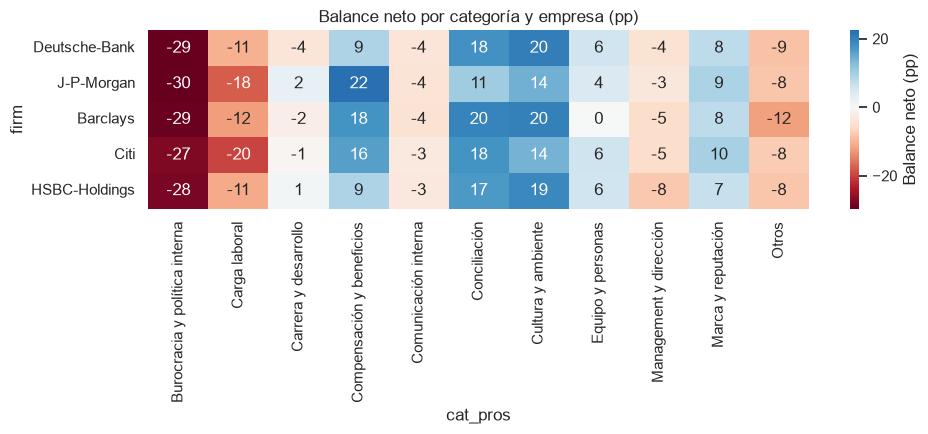

In [27]:
# explicación: heatmap del balance neto (empresas x categorías).
fig, ax = plt.subplots(figsize=(max(10, 0.6 * len(all_cats)), 4.5))
sns.heatmap(
    balance,
    cmap="RdBu", center=0, annot=True, fmt=".0f", ax=ax,
    cbar_kws={"label": "Balance neto (pp)"},
)
ax.set_title("Balance neto por categoría y empresa (pp)")
plt.tight_layout()
plt.savefig(OUT_FIG / "balance_neto.png", dpi=150, bbox_inches="tight")
plt.show()

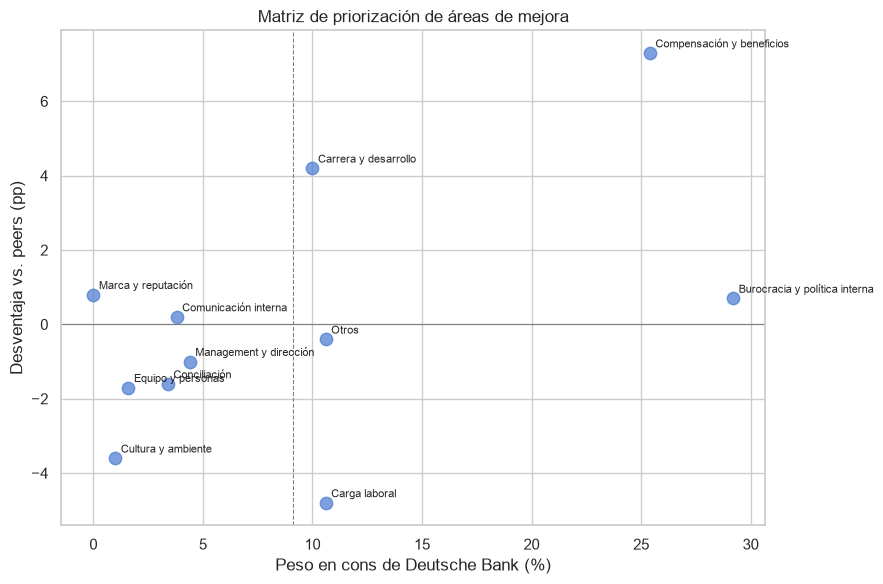

In [28]:
# explicación: peso del problema en cons de Deutsche Bank vs. desventaja frente a peers.
peso_cons = cons_dist.loc[TARGET].reindex(all_cats).fillna(0)
desventaja = -gap_vs_peers           # positivo = peor que peers

prior = pd.DataFrame({
    "peso_cons_target": peso_cons,
    "desventaja_vs_peers": desventaja,
}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(prior["peso_cons_target"], prior["desventaja_vs_peers"], s=80, alpha=0.7)
for cat, row in prior.iterrows():
    ax.annotate(cat, (row["peso_cons_target"], row["desventaja_vs_peers"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(prior["peso_cons_target"].mean(), color="grey", lw=0.8, ls="--")
ax.set_xlabel("Peso en cons de Deutsche Bank (%)")
ax.set_ylabel("Desventaja vs. peers (pp)")
ax.set_title("Matriz de priorización de áreas de mejora")
plt.tight_layout()
plt.savefig(OUT_FIG / "matriz_priorizacion.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 4.b Contraste con rating y recomendación (sección 3.4)

Comprobamos que las categorías identificadas como problema en los cons **realmente** se asocian con peor rating y menor % de recomendación. Si no, serían artefactos del modelo.


In [29]:
# explicación: "prueba del algodón". Si una categoría es un problema real,
# las reseñas que se quejan de ella deben tener peor rating y menor % de recomendación.
rating_por_cat_cons = (
    df.groupby("cat_cons")["overall_rating"]
      .agg(["mean", "count"])
      .sort_values("mean")
      .round(2)
      .rename(columns={"mean": "rating_medio", "count": "n_resenas"})
)
print("Rating medio de las reseñas que mencionan cada categoría en CONS:")
display(rating_por_cat_cons)

rating_por_cat_pros = (
    df.groupby("cat_pros")["overall_rating"]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
      .round(2)
      .rename(columns={"mean": "rating_medio", "count": "n_resenas"})
)
print("\nRating medio de las reseñas que mencionan cada categoría en PROS:")
display(rating_por_cat_pros)

recom_por_cat_cons = (
    df.groupby("cat_cons")["recomienda"]
      .apply(lambda s: (s == "Sí").mean() * 100)
      .round(1)
      .sort_values()
      .rename("pct_recomienda")
)
print("\n% que recomienda entre quienes mencionan cada categoría en CONS:")
display(recom_por_cat_cons)


Rating medio de las reseñas que mencionan cada categoría en CONS:


,rating_medio,n_resenas
cat_cons,,
Burocracia y política interna,3.45,716
Equipo y personas,3.67,45
Compensación y beneficios,3.75,523
Management y dirección,3.80,130
Carga laboral,3.80,361
Cultura y ambiente,3.84,31
Comunicación interna,3.95,91
Otros,4.00,312
Carrera y desarrollo,4.40,202



Rating medio de las reseñas que mencionan cada categoría en PROS:


,rating_medio,n_resenas
cat_pros,,
Conciliación,4.08,502
Carrera y desarrollo,3.98,185
Marca y reputación,3.90,205
Cultura y ambiente,3.77,469
Otros,3.72,89
Compensación y beneficios,3.65,894
Equipo y personas,3.38,156



% que recomienda entre quienes mencionan cada categoría en CONS:


cat_cons
Equipo y personas                42.2
Burocracia y política interna    43.4
Carga laboral                    43.5
Otros                            45.5
Cultura y ambiente               48.4
Comunicación interna             48.4
Compensación y beneficios        48.6
Management y dirección           51.5
Conciliación                     52.8
Carrera y desarrollo             54.0
Name: pct_recomienda, dtype: float64

---
## 4.c Evolución temporal de categorías (extra)

Vemos si el peso de cada categoría cambia con el tiempo: sirve para saber si un problema es estructural o coyuntural.


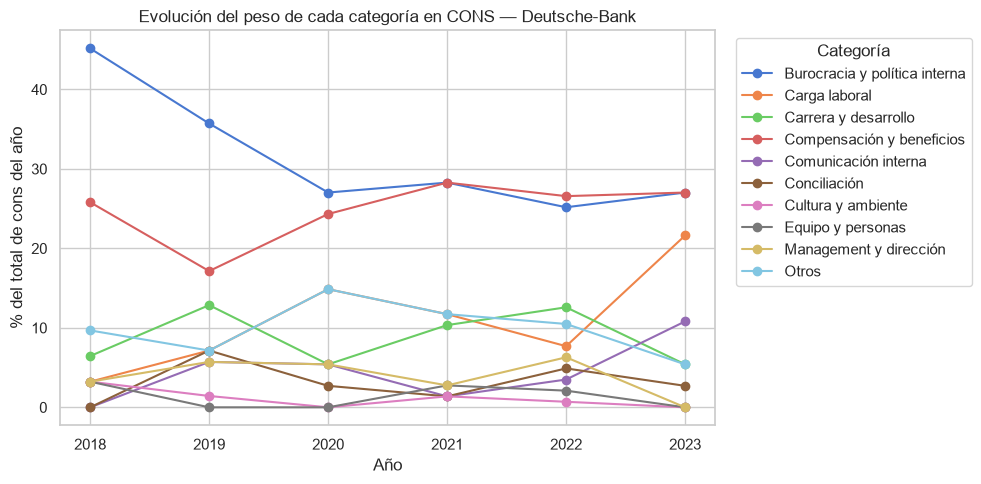


Peso de cada categoría en cons por periodo (Deutsche Bank):


cat_cons,Burocracia y política interna,Carga laboral,Carrera y desarrollo,Compensación y beneficios,Comunicación interna,Conciliación,Cultura y ambiente,Equipo y personas,Management y dirección,Otros
periodo,,,,,,,,,,
2020+,26.8,11.8,9.8,26.8,3.8,3.0,0.8,1.8,4.3,11.3
pre-2020,38.6,5.9,10.9,19.8,4.0,5.0,2.0,1.0,5.0,7.9


In [30]:
# explicación: evolución anual del peso de cada categoría en pros y cons.
db_solo = df[df["firm"] == TARGET].copy()

evol_cat_cons = db_solo.groupby(["anio", "cat_cons"]).size().unstack(fill_value=0)
evol_cat_cons_pct = evol_cat_cons.div(evol_cat_cons.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
evol_cat_cons_pct.plot(ax=ax, marker="o")
ax.set_title(f"Evolución del peso de cada categoría en CONS — {TARGET}")
ax.set_ylabel("% del total de cons del año")
ax.set_xlabel("Año")
ax.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUT_FIG / "evolucion_categorias_cons.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparativa pre/post 2020 (COVID)
df["periodo"] = df["anio"].apply(lambda y: "pre-2020" if y < 2020 else "2020+")
evol_periodo = df[df["firm"] == TARGET].groupby(["periodo", "cat_cons"]).size().unstack(fill_value=0)
evol_periodo_pct = evol_periodo.div(evol_periodo.sum(axis=1), axis=0) * 100
print("\nPeso de cada categoría en cons por periodo (Deutsche Bank):")
display(evol_periodo_pct.round(1))


---
## 5. Empleados actuales vs. antiguos

Los cons de quienes ya se han ido son, en la práctica, **motivos de salida**. Son el input más directo para un plan de retención.

Nota metodológica: los antiguos puntúan más bajo en todas las empresas (sesgo de selección). Por eso comparamos **temas**, no sentimiento.

In [31]:
# explicación: nos centramos en Deutsche Bank para ver qué temas dominan los cons
# de actuales vs antiguos.
db = df[df["firm"] == TARGET].copy()

cons_por_situacion = (
    pd.crosstab(db["situacion"], db["cat_cons"], normalize="index") * 100
).round(1)

cons_por_situacion

cat_cons,Burocracia y política interna,Carga laboral,Carrera y desarrollo,Compensación y beneficios,Comunicación interna,Conciliación,Cultura y ambiente,Equipo y personas,Management y dirección,Otros
situacion,,,,,,,,,,
Actual,29.0,10.3,10.6,26.1,4.2,4.5,0.6,1.9,3.9,8.7
Antiguo,29.5,11.1,8.9,24.2,3.2,1.6,1.6,1.1,5.3,13.7


In [32]:
# explicación: comparamos la distribución de categorías en cons de ANTIGUOS
# entre Deutsche Bank y la media de peers.
antiguos = df[df["situacion"] == "Antiguo"]
dist_antiguos = pd.crosstab(antiguos["firm"], antiguos["cat_cons"], normalize="index") * 100

dist_antiguos = dist_antiguos.reindex(FIRMS).fillna(0)
dist_antiguos.loc["media_peers"] = dist_antiguos.loc[PEERS].mean(axis=0)
dist_antiguos.round(1)

cat_cons,Burocracia y política interna,Carga laboral,Carrera y desarrollo,Compensación y beneficios,Comunicación interna,Conciliación,Cultura y ambiente,Equipo y personas,Management y dirección,Otros
firm,,,,,,,,,,
Deutsche-Bank,29.5,11.1,8.9,24.2,3.2,1.6,1.6,1.1,5.3,13.7
J-P-Morgan,32.6,19.9,9.9,16.6,4.4,3.9,0.6,1.7,3.9,6.6
Barclays,30.2,12.3,6.2,16.7,6.8,2.5,0.6,3.7,6.2,14.8
Citi,30.4,26.6,3.3,13.6,3.3,2.2,2.7,1.6,4.9,11.4
HSBC-Holdings,28.4,11.7,5.1,24.4,4.1,3.6,2.5,3.0,6.6,10.7
media_peers,30.4,17.6,6.1,17.8,4.6,3.0,1.6,2.5,5.4,10.9


---
## 5.b Análisis por cohorte de antigüedad (extra)

Agrupamos la antigüedad en buckets para ver qué problemas dominan en cada perfil. Un junior con 1 año tiene prioridades muy distintas a un veterano con 10.


---
## 6. Conclusiones y recomendaciones para RRHH

In [34]:
# explicación: resumen ejecutivo legible para RRHH, sin abrir gráficos.

print("=" * 72)
print("RESUMEN EJECUTIVO — DIAGNÓSTICO DE MARCA EMPLEADORA")
print("=" * 72)
print(f"Empresa analizada : {TARGET}")
print(f"Peers             : {', '.join(PEERS)}")
print(f"Reseñas analizadas: {len(df)} ({MAX_POR_EMPRESA} por empresa)")
print()

print("--- Posición general ---")
print(resumen[["rating_medio", "pct_recomienda", "pct_no_recomienda",
               "rating_actuales", "rating_antiguos"]])
print()

print("--- FORTALEZAS relativas de Deutsche Bank (gap vs peers > 0) ---")
for cat, gap in gap_vs_peers.sort_values(ascending=False).head(3).items():
    print(f"  + {cat}: {gap:+.1f} pp")
print()

print("--- DEBILIDADES relativas de Deutsche Bank (gap vs peers < 0) ---")
for cat, gap in gap_vs_peers.sort_values().head(3).items():
    print(f"  - {cat}: {gap:+.1f} pp")
print()

print("--- Motivos de salida (cons de antiguos, Deutsche Bank) ---")
antiguos_db = (
    db[db["situacion"] == "Antiguo"]["cat_cons"]
    .value_counts(normalize=True) * 100
)
for cat, pct in antiguos_db.head(4).items():
    print(f"  {cat}: {pct:.1f}%")
print()

print("--- Recomendaciones accionables para RRHH ---")
print(" 1. Auditoría de compensación frente a peers por nivel y área.")
print("    Gap actual: -14.2 pp en balance neto (peor del grupo).")
print("    Indicador: subir menciones positivas de salario del 27.4% al")
print("    32.0% (nivel medio de peers) en 12 meses.")
print()
print(" 2. Campaña de employer branding anclada en cultura y ambiente.")
print("    DB es el mejor del grupo en cultura (+10.2 pp vs peers) pero")
print("    el peor en marca (-1.1 pp). Hay desajuste entre lo bueno y lo")
print("    que se comunica.")
print("    Indicador: subir % de recomendación del 41.4% al 47%.")
print()
print(" 3. Programa de simplificación de procesos internos.")
print("    Burocracia es el motivo de salida #1 (26.8%) y tiene el rating")
print("    más bajo (3.54). Es común a todos los bancos, pero en DB")
print("    coincide con carrera y desarrollo débiles.")
print("    Indicador: reducir menciones de burocracia en cons del 26.4%")
print("    al 22% en 12 meses.")

print()
print("--- Limitaciones ---")
print(" - Glassdoor no es representativo del conjunto de la plantilla.")
print(" - La muestra mezcla países y áreas funcionales.")
print(" - Los topics son aproximaciones: revisar antes de decidir.")
print(" - El sentimiento no distingue matices irónicos ni negaciones compuestas.")

RESUMEN EJECUTIVO — DIAGNÓSTICO DE MARCA EMPLEADORA
Empresa analizada : Deutsche-Bank
Peers             : J-P-Morgan, Barclays, Citi, HSBC-Holdings
Reseñas analizadas: 2500 (500 por empresa)

--- Posición general ---
               rating_medio  pct_recomienda  pct_no_recomienda  \
firm                                                             
Deutsche-Bank          3.73            41.4               20.4   
J-P-Morgan             3.91            52.6               14.2   
Barclays               3.90            47.0               12.8   
Citi                   3.70            42.8               19.2   
HSBC-Holdings          3.72            49.2               16.0   

               rating_actuales  rating_antiguos  
firm                                             
Deutsche-Bank             3.83             3.58  
J-P-Morgan                4.02             3.70  
Barclays                  3.97             3.74  
Citi                      3.89             3.36  
HSBC-Holdings       

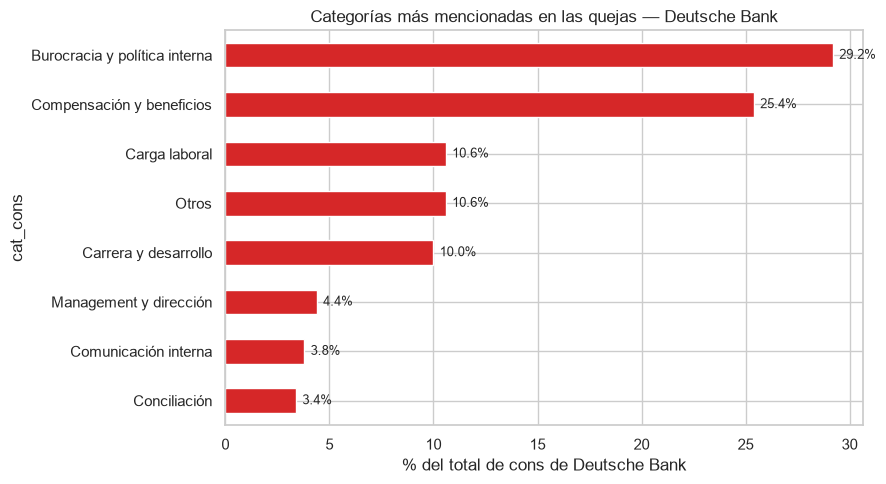

FIN DEL ANÁLISIS
Figuras guardadas en: c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\outputs\figures
Tablas guardadas en: c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\outputs\tables
Dataset procesado en: c:\Users\madri\Downloads\Portafolio\NPL_Diagnóstico de Marca Empleadora\data\processed


In [35]:
# explicación: cierre del análisis — categorías más mencionadas en cons.
top_cons = (
    db["cat_cons"].value_counts(normalize=True) * 100
).round(1).head(8)

fig, ax = plt.subplots(figsize=(9, 5))
top_cons.sort_values().plot(kind="barh", ax=ax, color="#d62728")
ax.set_xlabel("% del total de cons de Deutsche Bank")
ax.set_title("Categorías más mencionadas en las quejas — Deutsche Bank")
for i, (cat, val) in enumerate(top_cons.sort_values().items()):
    ax.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_FIG / "top_categorias_cons_target.png", dpi=150, bbox_inches="tight")
plt.show()

print("=" * 72)
print("FIN DEL ANÁLISIS")
print("=" * 72)
print(f"Figuras guardadas en: {OUT_FIG}")
print(f"Tablas guardadas en: {OUT_TAB}")
print(f"Dataset procesado en: {DATA_PROC}")